# Homework 10: Midterm 2 practice exam

This practice exam has four sections *in the same order as the exam.*
Each section has four short warm-ups followed by three questions about one code cell.
Predict each warm-up result before checking it in the [Homework 10 hints notebook](https://colab.research.google.com/github/wfreinhart/matse219/blob/main/notebooks/Homework10Hints.ipynb).
> Reading the cell's output isn't practice! You must predict it in advance.

Note that the exam itself won't include these "warm-up" sections.
The exam-style questions practice the same skills as the exam with different questions.

This homework will be graded for completion:
a genuine attempt at every part earns credit even if the answer is wrong.

You may also run the cells at the bottom to check and revise your answers.

## Submission instructions

Upload the `ipynb` file to Canvas:
> File -> Download -> ipynb -> upload to Canvas (like any other file)

The `ipynb` file type is the only accepted format.
Save a copy before beginning.
Reloading or disconnecting can revert the notebook to the instructor copy.

# Problem 0 (-10 pts if blank): generative AI usage statement

As you work on this assignment, feel free to use generative AI tools to help you learn,
understand, and debug Python code. In particular, you could get hints or conceptual guidance in
the implementation you write yourself.

However, you must clearly disclose and cite all use of AI. You must include:
1. The name(s) of the AI tool(s) used.
2. The specific prompt(s) you used to generate the content.
3. A description of how you used the output and what edits or additions you made to integrate it
   into your own work.

You are fully responsible for the final submitted work. Critically evaluate, fact-check, and
verify all AI-generated content for validity. Failure to properly cite and disclose AI use
constitutes plagiarism under Penn State's Academic Integrity policy.

Write your disclosure (or "I did not use an AI tool for this assignment") in the cell below.

*your disclosure here*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy import optimize

# 1. Functions, loops, and conditionals (25 points)

Five tensile specimens of a twill-weave composite, lowest strength first.
A part needs at least 750 MPa.
The code labels any specimen under 700 MPa weak.

*Data: NIST and U.S. Department of Energy ICME composite mechanical testing program (DE-EE0006867).*

## Warm-up (8 points)

**1a (2 points).** What does this print?
```python
def double(x):
    print(2 * x)

y = double(4)
print(y)
```

*your answer here*

**1b (2 points).** What does this print?
```python
def scale(value, factor=10):
    return value * factor

print(scale(3), scale(3, factor=2))
```

*your answer here*

**1c (2 points).** What does this print?
```python
def combine(a, b):
    return a - b, a + b

d, s = combine(9, 4)
print(d, s)
```

*your answer here*

**1d (2 points).** Fill in the keyword that ends the loop at the first value above 3.
```python
for v in [1, 2, 5, 3]:
    if v > 3:
        ________
    print(v)
```

*your answer here*

## Exam-style cell (17 points)

Read the code and its printed results before answering.
Values in `# prints` comments are shortened, as on the exam.

In [2]:
def check_strength(strength_MPa, limit_MPa=750):
    margin_MPa = np.round(strength_MPa - limit_MPa, 1)
    return margin_MPa, margin_MPa >= 0

specimens = [3, 1, 7, 2, 6]
strength_MPa = [680.3, 712.9, 735.7, 755.6, 806.7]

for i in range(len(specimens)):
    margin_MPa, passes = check_strength(strength_MPa[i])
    if strength_MPa[i] < 700:
        print(specimens[i], 'weak')
    elif passes:
        print(specimens[i], 'passes by', margin_MPa)
    else:
        print(specimens[i], 'short by', -margin_MPa)
# prints 3 weak
#        1 short by 37.1
#        7 short by 14.3
#        2 passes by 5.6
#        6 passes by 56.7

3 weak
1 short by 37.1
7 short by 14.3
2 passes by 5.6
6 passes by 56.7


**1e (6 points).** Specimen 3 prints `weak`, not `short by 69.7`. Why?

*your answer here*

**1f (6 points).** The loop calls `check_strength` with one value, but its definition names two inputs. Why does the call work?

*your answer here*

**1g (5 points).** Fill in the blank to store both values returned by `check_strength(806.7)` as `margin_MPa` and `passes`.
```python
________ = check_strength(806.7)
```

*your answer here*

# 2. Fitting with curve_fit (25 points)

`temperature` (in C) and `conductivity` (in mS/cm) hold 15 readings of a battery electrolyte, LiPF$_6$ salt in organic solvents.
The conductivity rises from 0.02 to about 11 mS/cm.
The code fits the model conductivity = a e$^{bT}$.

*Data: M. S. Ding, J. Chem. Eng. Data (2003), from the CALiSol-23 database (de Blasio et al., Scientific Data 11, 750, 2024; CC BY 4.0).*

## Warm-up (8 points)

**2a (2 points).** `optimize.curve_fit(model, x, y)` returned `popt` printing as `[3. 2.]`, for `def model(x, a, b):`. Which number is `b`?
```python
def model(x, a, b):
    return a * x**b

popt, pcov = optimize.curve_fit(model, x, y)
print(popt)   # prints [3. 2.]
```

*your answer here*

**2b (2 points).** Fill in the keyword that sets the starting values.
```python
popt, pcov = optimize.curve_fit(model, x, y, ____=[3, 2])
```

*your answer here*

**2c (2 points).** What does this print?
```python
def model(x, a, b):
    return a * x**b

print(model(2, *[1, 3]))
```

*your answer here*

**2d (2 points).** What does this print?
```python
popt = np.array([3.04, 0.2])   # two fitted values
print(popt.shape)
print(popt.round(1))
```

*your answer here*

## Exam-style cell (17 points)

Read the code and its printed results before answering.
Values in `# prints` comments are shortened, as on the exam.

Run this cell first.
It loads the data for the cell below.

In [3]:
#@title Load the electrolyte readings (click ▶ to run) { display-mode: "form" }
electrolyte = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/electrolyte_conductivity_lipf6.csv')
is_salt = electrolyte['molality_mol_per_kg'] == 0.5547
readings = electrolyte.loc[is_salt]
temperature = readings['temperature_K'].to_numpy() - 273.15
conductivity = readings['conductivity_mS_per_cm'].to_numpy()

In [4]:
def conductivity_model(T, a, b):
    """Conductivity in mS/cm from a * exp(b * T), with T in C."""
    return a * np.exp(b * T)

popt, pcov = optimize.curve_fit(conductivity_model, temperature, conductivity, p0=[3, 0.02])
print(popt)   # prints [3.6738 0.0202]

residuals = conductivity - conductivity_model(temperature, *popt)

[3.67381745 0.02023312]


Run this cell to draw the figure.

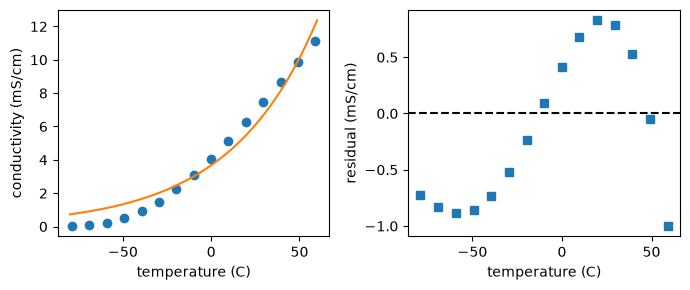

In [5]:
t_line = np.linspace(-80, 60, 200)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].plot(temperature, conductivity, 'o')
axes[0].plot(t_line, conductivity_model(t_line, *popt))
axes[0].set_xlabel('temperature (C)')
axes[0].set_ylabel('conductivity (mS/cm)')
axes[1].plot(temperature, residuals, 's')
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set_xlabel('temperature (C)')
axes[1].set_ylabel('residual (mS/cm)')
fig.tight_layout()
plt.show()

The left panel shows the readings (circles) and the curve from the first fit (line).
The right panel shows `residuals` of the first fit, the reading minus the curve.

**2e (6 points).** What does `conductivity_model(0, *popt)` return? Why does it equal the first fitted value?

*your answer here*

**2f (6 points).** What role does `p0=[3, 0.02]` play when the fit begins?

*your answer here*

**2g (5 points).** What would the residual panel look like if the model matched the trend and the only misses were measurement noise?

*your answer here*

# 3. Fitting with minimize (25 points)

`proof_GPa` (0.2% proof stress) and `tensile_GPa` (tensile strength) hold tests of 95 low-alloy steels at 27 C, in GPa.
The code fits the line tensile = a + b proof by minimizing the sum of squared residuals.

*Data: NIMS [MatNavi](https://mits.nims.go.jp/en/), tensile tests on low-alloy steels.*

## Warm-up (8 points)

**3a (2 points).** What does this print?
```python
def f(x):
    return (x - 4)**2

res = optimize.minimize(f, 1)
print(res.x[0].round(2))
```

*your answer here*

**3b (2 points).** What happens when this runs?
```python
def f(x):
    return (x - 4)**2

res = optimize.minimize(f, 1)
print(res.success())
```

*your answer here*

**3c (2 points).** Fill in the NumPy function that makes the objective a sum of squared residuals.
```python
def objective(params):
    residuals = y - model(x, *params)
    return np.________(residuals**2)
```

*your answer here*

**3d (2 points).** What does this print?
```python
def f(x):
    return (x - 2)**2 + 5

res = optimize.minimize(f, 0)
print(np.round(res.fun, 1))
```

*your answer here*

## Exam-style cell (17 points)

Read the code and its printed results before answering.
Values in `# prints` comments are shortened, as on the exam.

Run this cell first.
It loads the data for the cell below.

In [6]:
#@title Load the steel data (click ▶ to run) { display-mode: "form" }
steels = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/steels.csv')
at_27 = steels.loc[steels[' Temperature (°C)'] == 27]  # note the leading space in the column names
proof_GPa = at_27[' 0.2% Proof Stress (MPa)'].to_numpy() / 1000
tensile_GPa = at_27[' Tensile Strength (MPa)'].to_numpy() / 1000

In [7]:
def sum_sq(params):
    a, b = params
    tensile_model = a + b * proof_GPa
    residuals = tensile_GPa - tensile_model
    return np.sum(residuals**2)

res = optimize.minimize(sum_sq, [0, 1])
print(res.x)     # prints [0.23 0.83]

[0.2301056  0.82809393]


**3e (6 points).** The starting guess on line 7 is `[0, 1]`. What relationship between proof and tensile strength does it guess?

*your answer here*

**3f (6 points).** If two residuals had equal size and opposite signs, what would happen if `sum_sq` added them without squaring?

*your answer here*

**3g (5 points).** Write the replacement for line 5, the return line of `sum_sq`. It must return the mean absolute residual.

*your answer here*

# 4. Fitting a plane (25 points)

`cement` (kg/m$^3$), `age` (days) and `strength` (MPa) hold 234 concrete mixes that contain fly ash and no slag.
The code fits the plane strength = a + b cement + c age by minimizing the mean squared residual.
`rmse` is defined in the load cell below.

*Data: I-Cheng Yeh, Cement and Concrete Research 28 (1998) 1797-1808, via the UCI Machine Learning Repository (CC BY 4.0).*

## Warm-up (8 points)

**4a (2 points).** What does this print?
```python
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(0, 1, 3, 4, 5))
```

*your answer here*

**4b (2 points).** Fill in the keyword that colors each point by the values in `z`.
```python
fig, ax = plt.subplots()
ax.scatter(x, y, ____=z, cmap='viridis')
```

*your answer here*

**4c (2 points).** What does this print?
```python
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(1, 0, *[3, 4, 5]))
```

*your answer here*

**4d (2 points).** What happens when this runs?
```python
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(1, 0, [3, 4, 5]))
```

*your answer here*

## Exam-style cell (17 points)

Read the code and its printed results before answering.
Values in `# prints` comments are shortened, as on the exam.

Run this cell first.
It loads the data for the cell below.

In [8]:
#@title Load the concrete data (click ▶ to run) { display-mode: "form" }
data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/concrete.csv')
data.columns = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
                'coarse_agg', 'fine_agg', 'age', 'strength']
is_fly_ash = (data['fly_ash'] > 0) & (data['slag'] == 0)
mixes = data.loc[is_fly_ash]
cement = mixes['cement']
age = mixes['age']
strength = mixes['strength']

def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    return np.sqrt(np.mean((y - y_fit)**2))

In [9]:
def plane(x, y, a, b, c):
    return a + b * x + c * y

def mse_plane(params):
    a, b, c = params
    residuals = strength - plane(cement, age, a, b, c)
    return np.mean(residuals**2)

res = optimize.minimize(mse_plane, [0, 0, 0])

print(rmse(strength, np.mean(strength)))      # prints 13.41
print(np.max(age))                                     # prints 100

13.414760697890205
100


**4e (6 points).** What does `mse_plane` return for one choice of `a`, `b` and `c`?

*your answer here*

**4f (6 points).** Line 11 prints 13.41 for `rmse(strength, np.mean(strength))`. What does that number measure?

*your answer here*

**4g (5 points).** Line 12 prints the largest age in the data. Fill in the blank to print the smallest age.
```python
print(np.____(age))
```

*your answer here*